# Sound scattering layer detector: demo

Supporting material for Barstein, Rogge, Olaisen, Abdelgayed, Dunn, Stevenson-Jones, Davies, Grimsmo and
Ludvigsen, *A Remote Operations Center Framework for Heterogeneous Robotic Zooplankton Sampling: System
Design and Field Case Study*.

This notebook runs the per-ping scattering-layer detector described in the paper on two stretches of
AutoNaut echosounder data, a simple one and a harder one. The detector follows the principle of the Peaks
method of Peña et al. (2021): a layer is a peak in the smoothed Sv profile of a single ping, and its edges
mark the layer's vertical extent. The notebook shows what each setting does, and it ends with a panel
where you can tune the settings yourself. The detector itself is in `ssl_detector.py`.

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
from functools import lru_cache

import ipywidgets as w
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

import ssl_detector as ssl

NAMES = {"tue_night": "Tuesday night (simple)", "wed_night": "Wednesday night (harder)"}
D = {k: ssl.load_data(f"data/autonaut_{k}.npz") for k in NAMES}
for k, d in D.items():
    print(f"{NAMES[k]}: {len(d['time'])} pings, {d['time'][0]} to {d['time'][-1]} UTC, "
          f"depth {d['depth'][0]:.2f} to {d['depth'][-1]:.2f} m in 0.1 m bins")

Tuesday night (simple): 2931 pings, 2024-06-05T00:30:02.679 to 2024-06-05T02:59:57.776 UTC, depth 0.45 to 99.95 m in 0.1 m bins
Wednesday night (harder): 5200 pings, 2024-06-05T21:26:00.653 to 2024-06-06T01:45:57.656 UTC, depth 0.45 to 99.95 m in 0.1 m bins


## The data

Both stretches come from the AutoNaut uncrewed surface vehicle (NTNU) off Mausund/Frøan, Norway, in June 2024:
a Simrad EK80 WBT Mini with a 200 kHz split-beam transducer (ES200-7CDK), CW pulses of 1.024 ms, about one
ping every 3 s, not calibrated. Sv (dB re 1 m⁻¹) was computed with Echopype (Lee et al. 2024) and averaged
into 0.1 m depth bins (mean of the linear values). Depth is the range from the transducer.

- **Tuesday night** (5 June 00:30 to 03:00 UTC, 2931 pings): one layer near 20 m. From about 01:45 the seabed
  rises into the depth range, from 100 m to about 60 m.
- **Wednesday night** (5 June 21:26 to 6 June 01:46 UTC, 5200 pings): a layer that moves up and down between
  about 45 and 90 m, in deeper water.

The echosounder was not calibrated, so the absolute Sv values, and with them the thresholds below, apply to
this instrument only.

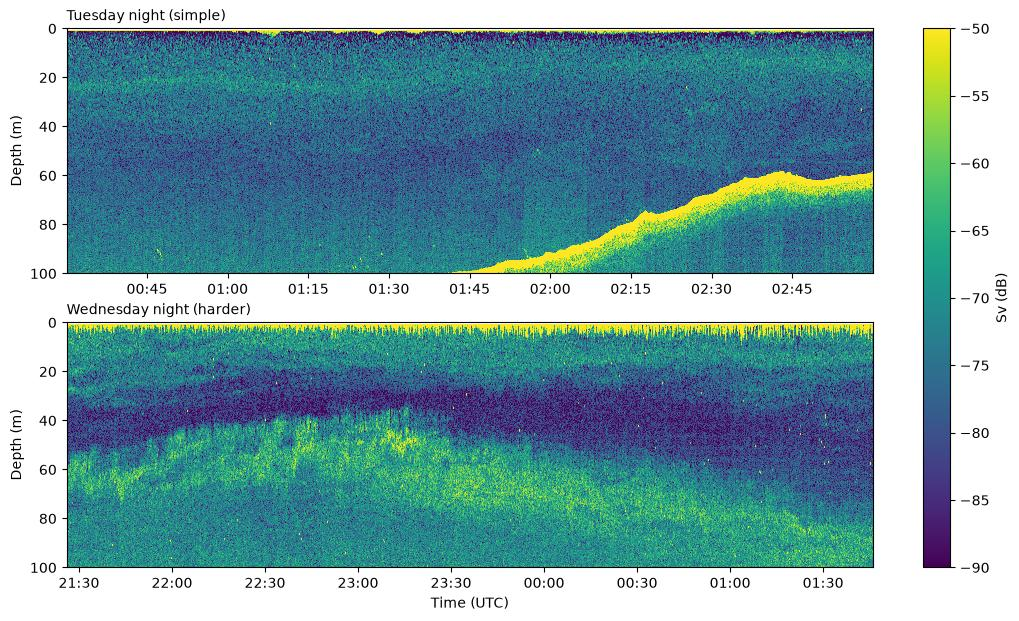

In [2]:
T = {k: mdates.date2num(d["time"]) for k, d in D.items()}


def echogram(ax, k, r=None, median=1, title=None):
    """Echogram of dataset k, with the detected bounds (white) and peak (red) of result r."""
    d = D[k]
    im = ax.imshow(d["sv"].T, aspect="auto", cmap="viridis", vmin=-90, vmax=-50, interpolation="nearest",
                   extent=[T[k][0], T[k][-1], d["depth"][-1], d["depth"][0]])
    if r is not None:
        for key, c in (("z_u", "w"), ("z_l", "w"), ("z_peak", "r")):
            ax.plot(T[k], ssl.running_median(r[key], median), ".", ms=1, color=c)
    ax.set_ylim(100, 0)
    ax.xaxis_date()
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.set_ylabel("Depth (m)")
    ax.set_title(title or NAMES[k], fontsize=10, loc="left")
    return im


fig, axs = plt.subplots(2, 1, figsize=(13, 7))
for ax, k in zip(axs, D):
    im = echogram(ax, k)
axs[-1].set_xlabel("Time (UTC)")
fig.colorbar(im, ax=axs, label="Sv (dB)")
plt.show()

In both echograms the top few metres hold the echo near the transducer (ring-down), which is very strong.
On Tuesday the seabed is the bright yellow band coming up from the bottom right.

## The detector

The peaks and their edges are found with SciPy (Virtanen et al. 2020). For each ping:

1. Keep the profile within the depth range, `min_depth` to `max_depth`.
2. Smooth it along depth with a Gaussian filter of width `sigma`.
3. Mask strong echoes: values at or above `sv_max` (seafloor, fish school, the echo near the transducer) are
   left out, and the layer is searched in each stretch of the profile between them.
4. Find the layer peaks with `scipy.signal.find_peaks`: local maxima with Sv at or above `sv_min`, that stand
   at least `min_prominence` above their surroundings and are at least `min_width` thick. With `floor`, the
   profile is first raised to `sv_min`.
5. Keep the main layer peak, the most prominent one.
6. Its edges give the upper bound `z_u` and the lower bound `z_l`. They are read where the profile has dropped
   by `rel_height` times the peak's prominence (as `scipy.signal.peak_widths` measures them).
7. Intensity: `I = (Sv_peak - sv_min) / (sv_max - sv_min)`, clipped to 0 to 1.

Two sets of settings are given in `ssl_detector.py`:

- **Case study** (`ssl.DEFAULTS`): the settings of the paper's case study, chosen by a parameter sweep. The
  three extra peak tests (`min_prominence`, `min_width`, `floor`) are off.
- **Tuned** (`ssl.TUNED`): tuned by hand on other stretches of the same survey (among them the Thursday CW
  data, which are not included here). They work well on most stretches, but not on Wednesday night
  (section 9). They are meant to be used with a running median
  over 23 pings (`ssl.TUNED_MEDIAN`).

In [3]:
CASE, TUNED = ssl.DEFAULTS, ssl.TUNED
SETTINGS = {"case study": CASE, "tuned": TUNED}
USE = {"tue_night": "tuned", "wed_night": "case study"}     # the settings each dataset is shown with
print(f"{'':16}" + "".join(f"{name:>12}" for name in SETTINGS))
for key in CASE:
    print(f"{key:16}" + "".join(f"{str(s[key]):>12}" for s in SETTINGS.values()))

                  case study       tuned
min_depth                2.5         2.5
max_depth              100.0        81.5
sigma                    3.1         2.0
sv_min                 -84.0       -80.0
sv_max                 -52.5       -60.5
rel_height              0.95        0.95
min_prominence           0.0         1.0
min_width                0.0         1.0
floor                  False        True


In [4]:
def settings(k, **kw):
    """The settings dataset k is shown with, changed by kw."""
    return {**SETTINGS[USE[k]], **kw}


def profile(ax, k, i, legend=True, p=None, **kw):
    """Ping i of dataset k: Sv, the smoothed profile, the thresholds and the detected layer."""
    p = p or settings(k, **kw)
    d = D[k]
    s, z = ssl.smooth(d["sv"][i], d["depth"], p["min_depth"], p["max_depth"], p["sigma"])
    r = ssl.find_layer(s, z, p["sv_min"], p["sv_max"], p["rel_height"], p["min_prominence"], p["min_width"],
                       p["floor"])
    ax.axhspan(0, p["min_depth"], color="0.92")
    ax.axhspan(p["max_depth"], 100, color="0.92")
    ax.plot(d["sv"][i], d["depth"], color="0.7", lw=0.7, label="Sv")
    searched = np.maximum(s, p["sv_min"]) if p["floor"] else s
    ax.plot(np.where(s < p["sv_max"], searched, np.nan), z, "k", lw=1.5, label="smoothed, searched")
    ax.plot(np.where(s >= p["sv_max"], s, np.nan), z, color="tab:red", lw=3, alpha=0.5, label="masked (strong echo)")
    ax.axvline(p["sv_min"], color="tab:blue", ls="--", lw=1, label="Sv_min")
    ax.axvline(p["sv_max"], color="tab:red", ls="--", lw=1, label="Sv_max")
    if r["found"]:
        ax.axhspan(r["z_u"], r["z_l"], color="tab:orange", alpha=0.3, label="layer, z_u to z_l")
        ax.plot(r["sv_peak"], r["z_peak"], "o", color="tab:orange", label="Sv_peak")
    ax.set_xlim(-100, -30)
    ax.set_ylim(100, 0)
    ax.set_xlabel("Sv (dB)")
    ax.set_title(f"{NAMES[k].split(' (')[0]}, {str(d['time'][i])[11:19]} UTC", fontsize=10)
    if legend:
        ax.legend(fontsize=8, loc="lower right")
    return r


def ping_at(k, hhmm):
    """Index of the ping of dataset k closest to the time hh:mm."""
    day = str(D[k]["time"][0])[:10] if hhmm >= "12:00" else str(D[k]["time"][-1])[:10]
    return int(np.argmin(np.abs(T[k] - mdates.date2num(np.datetime64(f"{day}T{hhmm}")))))


EX = {"tue_night": ping_at("tue_night", "02:30"),   # layer near 20 m, seabed in range
      "wed_night": ping_at("wed_night", "23:00")}   # layer near 50 m


def panels(title, values, unit=""):
    """The example ping of each dataset (rows), with the setting `title` at each of `values` (columns)."""
    fig, axs = plt.subplots(2, len(values), figsize=(4.4 * len(values), 9), sharey=True, squeeze=False)
    for row, k in zip(axs, D):
        for ax, v in zip(row, values):
            profile(ax, k, EX[k], legend=False, **{title: v})
            ax.set_title(f"{NAMES[k].split(' (')[0]} ({USE[k]}): {title} = {v}{unit}", fontsize=10)
        row[0].set_ylabel("Depth (m)")
    labels = {}
    for ax in axs.flat:
        for h, l in zip(*ax.get_legend_handles_labels()):
            labels.setdefault(l, h)
    fig.legend(labels.values(), labels.keys(), loc="lower center", ncol=4, fontsize=9)
    fig.subplots_adjust(bottom=0.13, hspace=0.3)
    return axs


def table(title, values, cols):
    """Run the detector on all pings of both datasets for each value of one setting and print `cols`."""
    for k in D:
        print(f"{NAMES[k]}, {USE[k]} settings")
        for v in values:
            r = ssl.detect(D[k]["sv"], D[k]["depth"], **settings(k, **{title: v}))
            print(f"  {title} {str(v):>6}: " + ", ".join(f(r) for f in cols))


found = lambda r: f"layer in {100 * r['found'].mean():5.1f}% of pings"
thick = lambda r: f"median thickness {np.nanmedian(r['z_l'] - r['z_u']):5.1f} m"
peak = lambda r: f"median peak depth {np.nanmedian(r['z_peak']):5.1f} m"
jump = lambda r: f"median jump of the peak between pings {np.nanmedian(np.abs(np.diff(r['z_peak']))):4.1f} m"
inten = lambda r: f"median I {np.median(r['intensity'][r['found']]) if r['found'].any() else 0:.2f}"

In the plots below, each row is one ping of one dataset: Tuesday with the tuned settings, Wednesday with the
case-study settings, and one setting changed across the columns. The grey line is the ping's Sv and the black
line is the smoothed profile the detector searches. The red band marks masked strong echoes, and the orange
band is the detected layer. Grey shading marks depths outside the depth range. Below each figure, the same
change is run on all pings of each dataset.

## 1. Depth range: `min_depth`, `max_depth`

Only this part of the profile is searched. The top keeps the echo near the transducer out of the search;
where that echo is still at or above `sv_max` after smoothing, it is masked anyway. The top also changes which
peak wins, because a shallow layer's prominence is measured against the profile above it. On Tuesday a top at
10 m cuts off the upper flank of the 20 m layer, and the main peak moves to a weaker bump near 50 m in a
quarter of the pings (right panel). The bottom (100 m in the case study, the operational depth; 81.5 m in the
tuned settings) can end the search above the seabed, but it also cuts off a layer that sinks below it, as on
Wednesday.

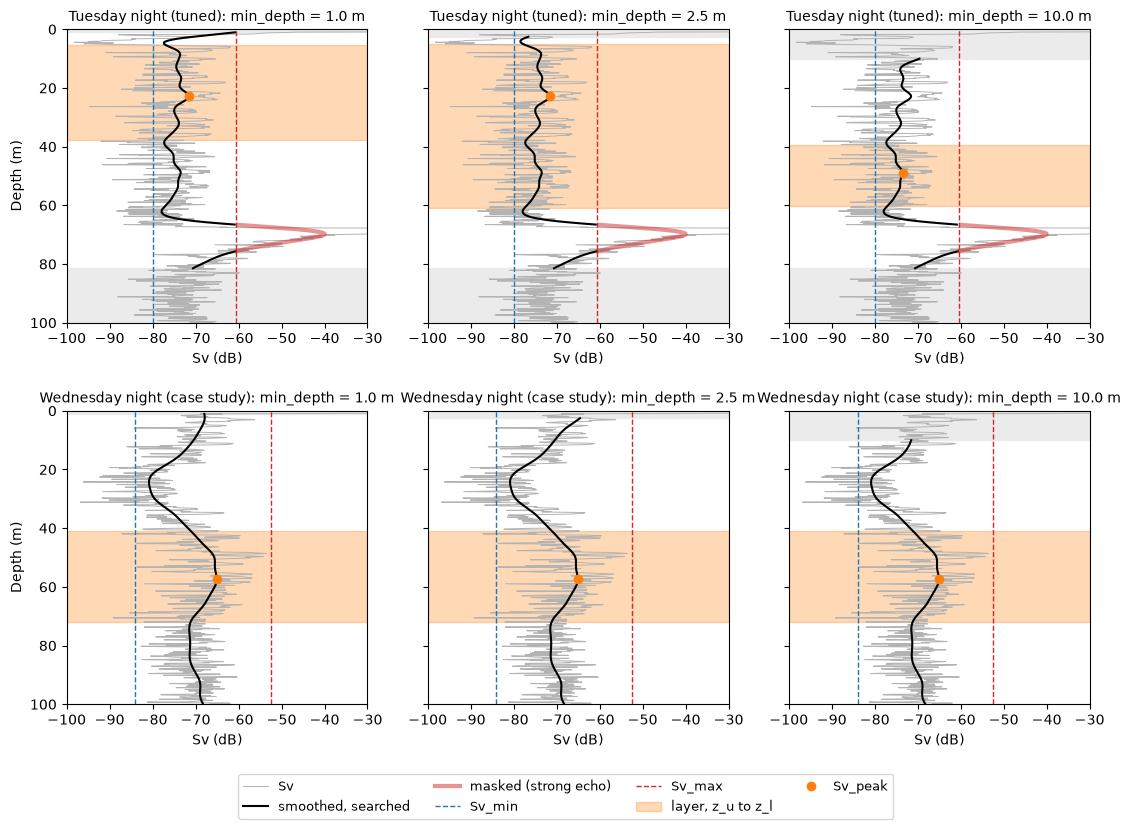

Tuesday night (simple), tuned settings


  min_depth    1.0: layer in 100.0% of pings, median peak depth  18.4 m


  min_depth    2.5: layer in 100.0% of pings, median peak depth  18.1 m


  min_depth    5.0: layer in  99.9% of pings, median peak depth  19.9 m


  min_depth   10.0: layer in  99.2% of pings, median peak depth  23.8 m
Wednesday night (harder), case study settings


  min_depth    1.0: layer in 100.0% of pings, median peak depth  64.8 m


... (5 outputs left out)

  max_depth  100.0: layer in 100.0% of pings, median peak depth  18.1 m
Wednesday night (harder), case study settings


  max_depth   60.0: layer in  86.3% of pings, median peak depth  38.8 m


  max_depth   81.5: layer in  98.2% of pings, median peak depth  60.0 m


  max_depth  100.0: layer in 100.0% of pings, median peak depth  64.7 m


In [5]:
panels("min_depth", (1.0, 2.5, 10.0), " m")
plt.show()
table("min_depth", (1.0, 2.5, 5.0, 10.0), (found, peak))
table("max_depth", (60.0, 81.5, 100.0), (found, peak))

## 2. Smoothing: `sigma`

The width (standard deviation, in metres) of the Gaussian filter applied along depth to the dB values. A
single ping is noisy, so without enough smoothing the layer breaks into small peaks, and the main peak jumps
between them from ping to ping. With too much smoothing, nearby layers merge into one and the edges blur.
It also spreads the seabed echo, so its smoothed peak drops below `sv_max`: the seabed is then not masked and
is taken as the layer (Tuesday, right panel). With `sigma` = 8 m, Tuesday's peak is deeper than 55 m in 18% of
the pings, against 0.8% at 3.1 m, so the smaller jump at 8 m comes partly from following the seabed.

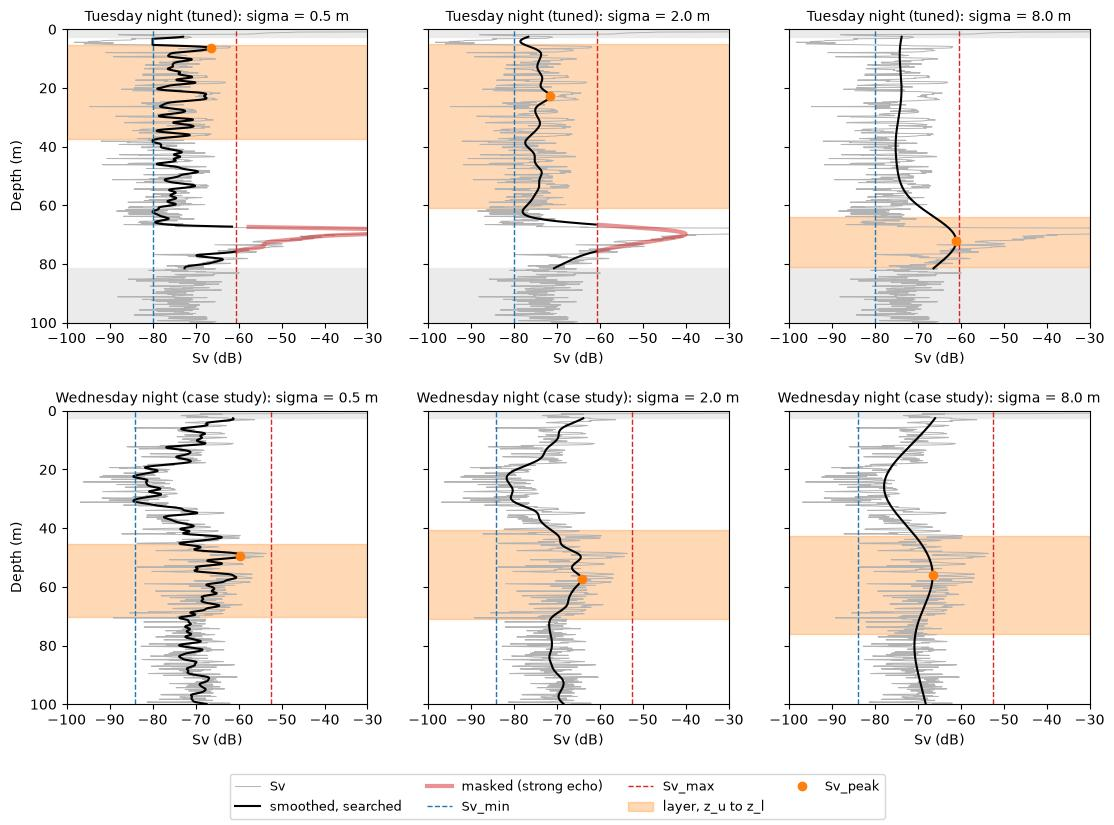

Tuesday night (simple), tuned settings


  sigma    0.5: layer in 100.0% of pings, median thickness  19.7 m, median jump of the peak between pings  4.4 m


  sigma    2.0: layer in 100.0% of pings, median thickness  36.7 m, median jump of the peak between pings  2.5 m


  sigma    3.1: layer in  99.8% of pings, median thickness  36.6 m, median jump of the peak between pings  2.2 m


  sigma    8.0: layer in  88.7% of pings, median thickness  34.5 m, median jump of the peak between pings  1.4 m
Wednesday night (harder), case study settings


  sigma    0.5: layer in 100.0% of pings, median thickness  23.9 m, median jump of the peak between pings  5.6 m


  sigma    2.0: layer in 100.0% of pings, median thickness  29.8 m, median jump of the peak between pings  2.6 m


  sigma    3.1: layer in 100.0% of pings, median thickness  30.0 m, median jump of the peak between pings  2.1 m


  sigma    8.0: layer in  89.8% of pings, median thickness  30.4 m, median jump of the peak between pings  1.5 m


In [6]:
panels("sigma", (0.5, 2.0, 8.0), " m")
plt.show()
table("sigma", (0.5, 2.0, 3.1, 8.0), (found, thick, jump))

## 3. Lower threshold: `sv_min`

Peaks weaker than `sv_min` are background. It is also the bottom of the intensity scale (I = 0). It changes
little until it comes close to the layer's own peak, which is weaker on Tuesday than on Wednesday.

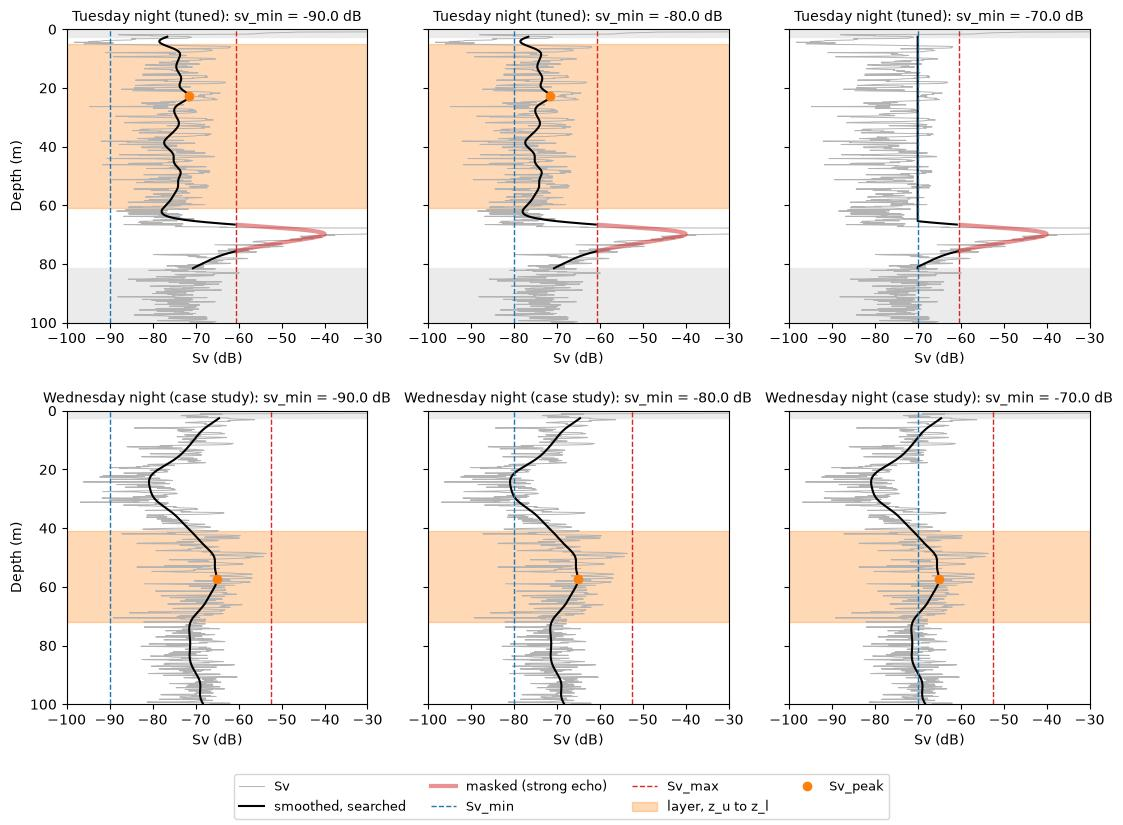

Tuesday night (simple), tuned settings


  sv_min  -90.0: layer in 100.0% of pings, median I 0.63


  sv_min  -84.0: layer in 100.0% of pings, median I 0.53


  sv_min  -80.0: layer in 100.0% of pings, median I 0.43


  sv_min  -76.0: layer in  99.6% of pings, median I 0.29


  sv_min  -72.0: layer in  34.2% of pings, median I 0.15


... (3 outputs left out)

  sv_min  -80.0: layer in  99.9% of pings, median I 0.53


  sv_min  -76.0: layer in  99.5% of pings, median I 0.46


  sv_min  -72.0: layer in  99.3% of pings, median I 0.34


  sv_min  -66.0: layer in  65.2% of pings, median I 0.13


In [7]:
panels("sv_min", (-90.0, -80.0, -70.0), " dB")
plt.show()
table("sv_min", (-90.0, -84.0, -80.0, -76.0, -72.0, -66.0), (found, inten))

## 4. Upper threshold: `sv_max`

Echoes at or above `sv_max` are treated as the seafloor, a dense school or the echo near the transducer. They
are masked: left out of the search, while the rest of the profile, above and below them, is still searched.
It is also the top of the intensity scale (I = 1).

- **Tuesday:** the seabed is masked where its smoothed echo reaches `sv_max`. At −45 dB it is not masked and
  is taken as the layer (right panel). With all the case-study settings (`sigma` 3.1 m, `sv_max` −52.5 dB) this
  happens in 77 pings (2.6%), nearly all between 02:47 and 02:58, where the smoothed seabed echo peaks at only
  −52.5 to −56 dB (section 9). The tuned −60.5 dB masks it.
- **Wednesday:** the seabed is deeper than 100 m, so only the echo near the transducer is masked, and
  `sv_max` changes little until it comes close to the layer's own strongest parts.

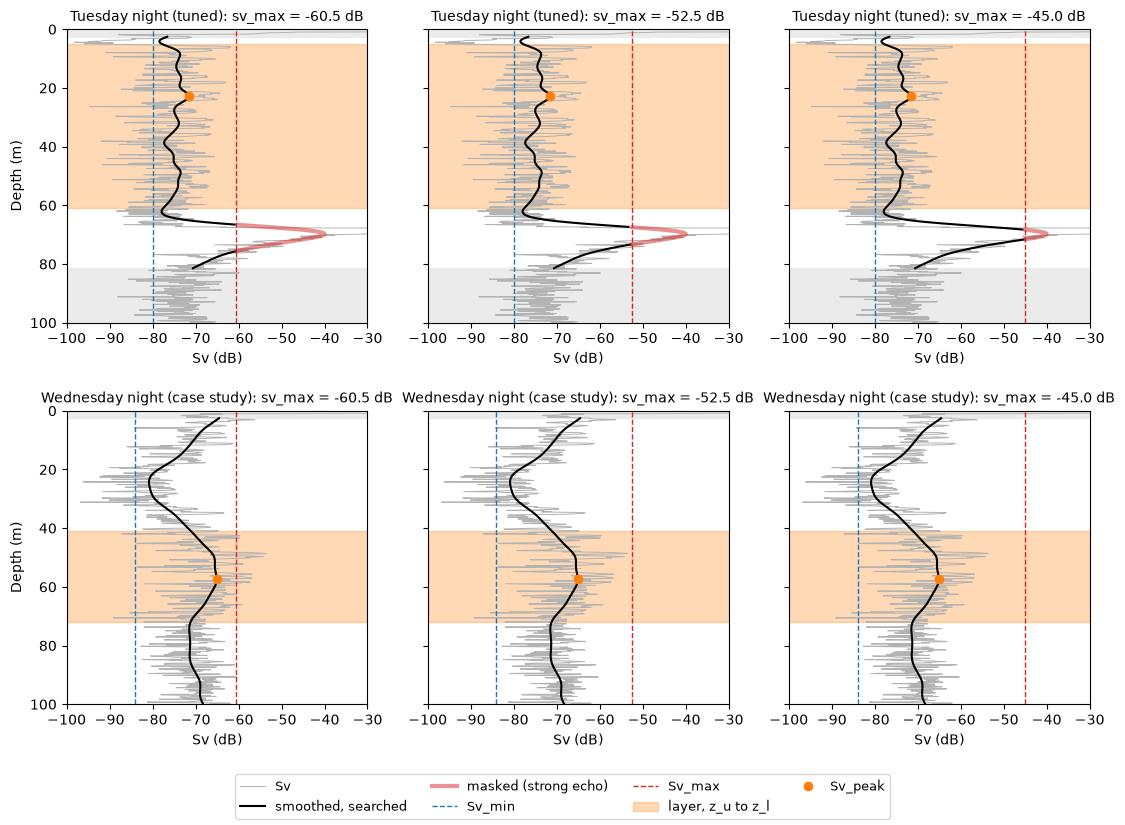

Tuesday night (simple), tuned settings


  sv_max  -60.5: layer in 100.0% of pings, median peak depth  18.1 m, peak deeper than 55 m and above -60 dB (on Tuesday, the seabed) in    0 pings


  sv_max  -52.5: layer in 100.0% of pings, median peak depth  18.1 m, peak deeper than 55 m and above -60 dB (on Tuesday, the seabed) in    0 pings


  sv_max  -45.0: layer in 100.0% of pings, median peak depth  19.1 m, peak deeper than 55 m and above -60 dB (on Tuesday, the seabed) in  159 pings
Wednesday night (harder), case study settings


  sv_max  -60.5: layer in  99.8% of pings, median peak depth  64.7 m, peak deeper than 55 m and above -60 dB (on Tuesday, the seabed) in    0 pings


  sv_max  -52.5: layer in 100.0% of pings, median peak depth  64.7 m, peak deeper than 55 m and above -60 dB (on Tuesday, the seabed) in   16 pings


  sv_max  -45.0: layer in 100.0% of pings, median peak depth  64.7 m, peak deeper than 55 m and above -60 dB (on Tuesday, the seabed) in   16 pings


In [8]:
panels("sv_max", (-60.5, -52.5, -45.0), " dB")
plt.show()
seabed = lambda r: f"peak deeper than 55 m and above -60 dB (on Tuesday, the seabed) in {np.sum((r['z_peak'] > 55) & (r['sv_peak'] > -60)):4d} pings"
table("sv_max", (-60.5, -52.5, -45.0), (found, peak, seabed))

## 5. Where the bounds are read: `rel_height`

The bounds are where the smoothed profile has dropped below the peak by `rel_height` times the peak's
prominence (how far the peak stands above its surroundings). 0.5 gives the half-prominence width; values
near 1 reach down to the background on either side, which on Tuesday is close to the surface.

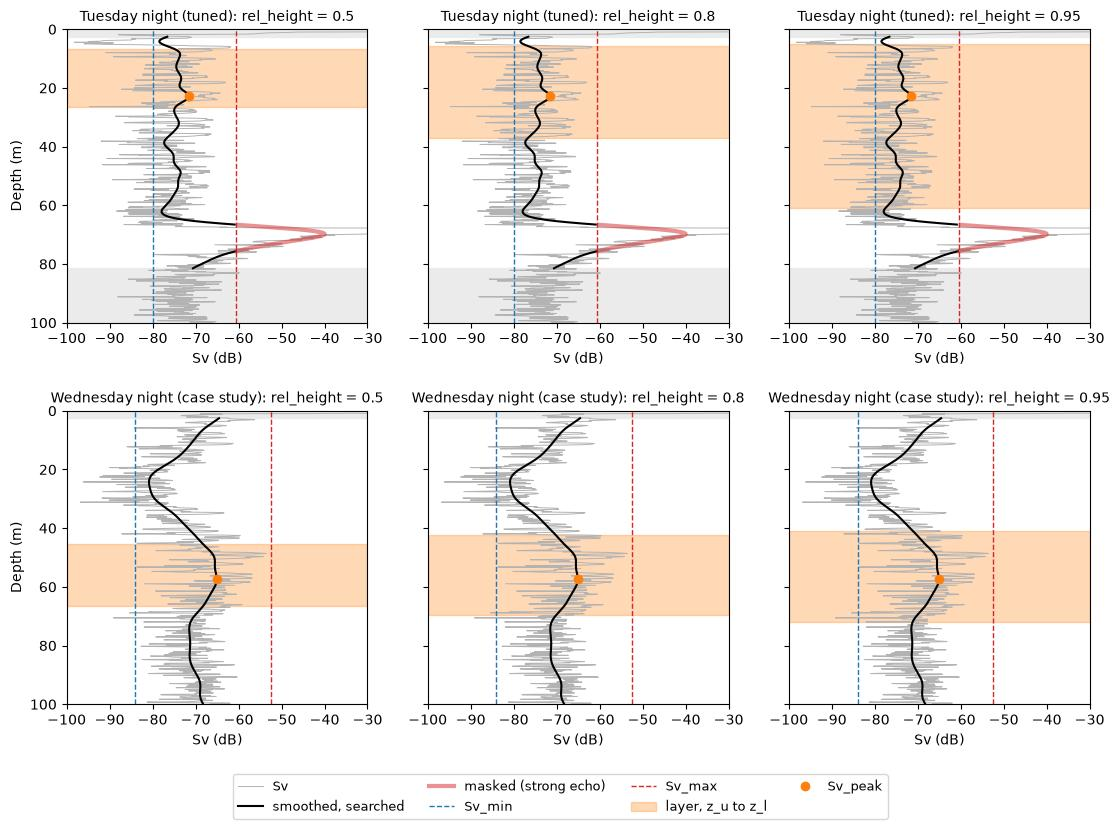

Tuesday night (simple), tuned settings


  rel_height    0.5: median thickness  15.3 m


  rel_height    0.8: median thickness  28.6 m


  rel_height   0.95: median thickness  36.7 m
Wednesday night (harder), case study settings


  rel_height    0.5: median thickness  14.9 m


  rel_height    0.8: median thickness  24.6 m


  rel_height   0.95: median thickness  30.0 m


In [9]:
panels("rel_height", (0.5, 0.8, 0.95))
plt.show()
table("rel_height", (0.5, 0.8, 0.95), (thick,))

## 6. Minimum prominence: `min_prominence`

How far, in dB, a peak must stand above its surroundings (scipy's prominence: the height of the peak above
the higher of the two lowest points between it and any higher part of the profile on either side). It
removes small bumps on the layer's flanks and in the background. If the layer itself stands out less than
this, no layer is found. On Wednesday the layer stands out less from its surroundings than on Tuesday, so the
same `min_prominence` removes more pings.

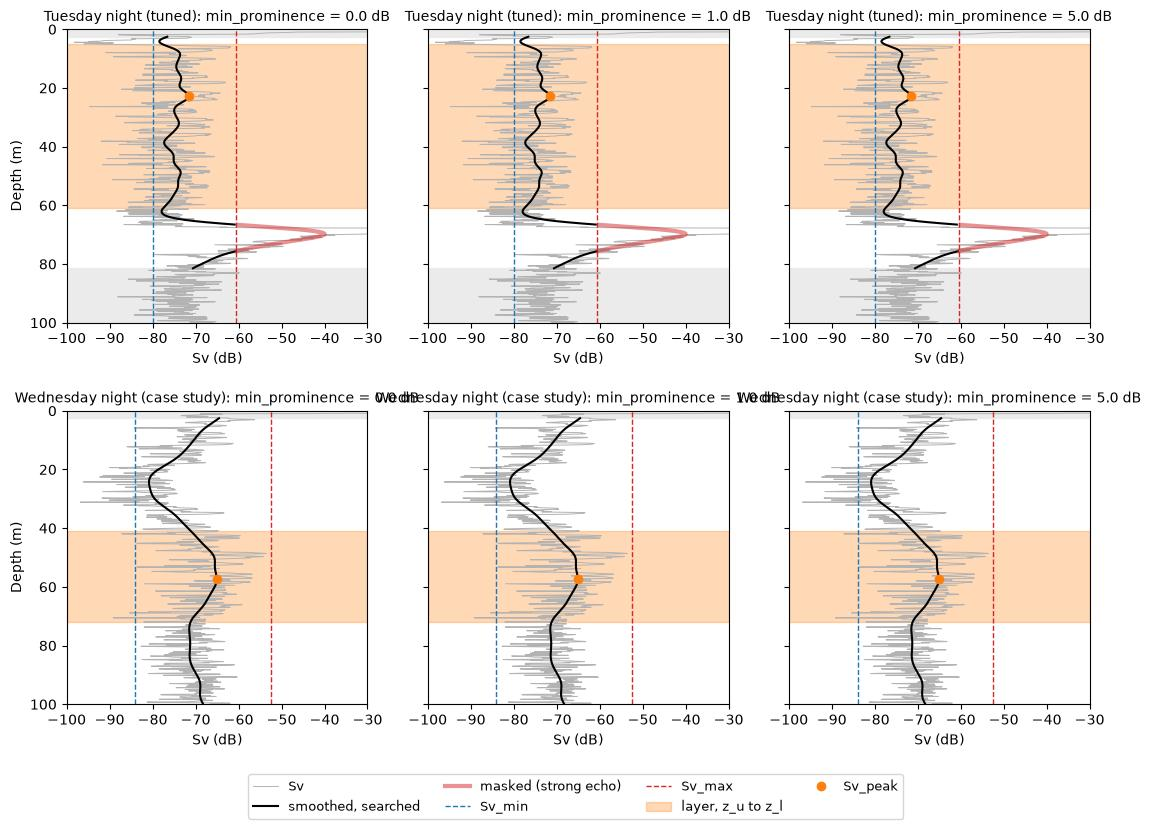

Tuesday night (simple), tuned settings


  min_prominence    0.0: layer in 100.0% of pings, median jump of the peak between pings  2.5 m


  min_prominence    1.0: layer in 100.0% of pings, median jump of the peak between pings  2.5 m


  min_prominence    3.0: layer in  99.3% of pings, median jump of the peak between pings  2.5 m


  min_prominence    5.0: layer in  92.7% of pings, median jump of the peak between pings  2.4 m
Wednesday night (harder), case study settings


  min_prominence    0.0: layer in 100.0% of pings, median jump of the peak between pings  2.1 m


  min_prominence    1.0: layer in  97.1% of pings, median jump of the peak between pings  2.0 m


  min_prominence    3.0: layer in  85.4% of pings, median jump of the peak between pings  1.8 m


  min_prominence    5.0: layer in  67.5% of pings, median jump of the peak between pings  1.8 m


In [10]:
panels("min_prominence", (0.0, 1.0, 5.0), " dB")
plt.show()
table("min_prominence", (0.0, 1.0, 3.0, 5.0), (found, jump))

## 7. Minimum width: `min_width`

The minimum thickness of a peak in metres, measured at `rel_height`. It removes thin peaks, such as a single
fish or a thin bump left after smoothing. Both layers here are tens of metres thick, so it matters little
until about 10 m.

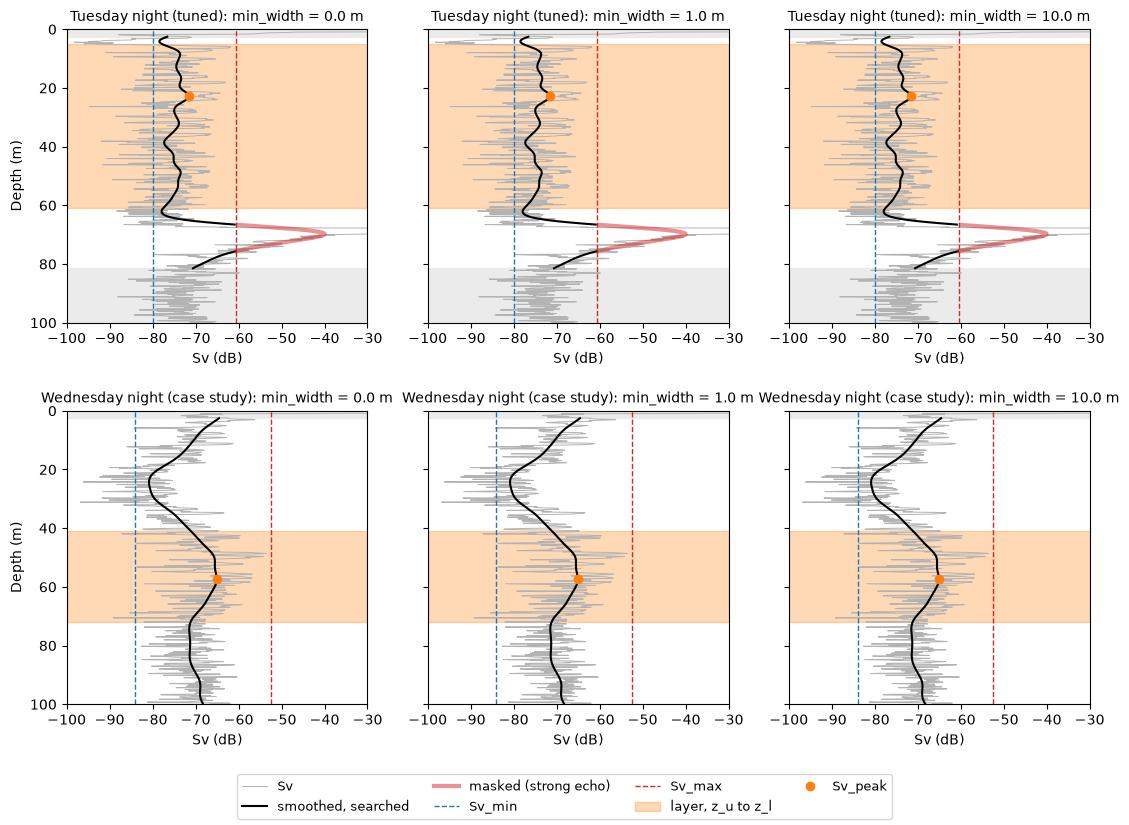

Tuesday night (simple), tuned settings


  min_width    0.0: layer in 100.0% of pings, median thickness  36.7 m


  min_width    1.0: layer in 100.0% of pings, median thickness  36.7 m


  min_width    5.0: layer in 100.0% of pings, median thickness  36.7 m


  min_width   10.0: layer in  99.9% of pings, median thickness  36.7 m
Wednesday night (harder), case study settings


  min_width    0.0: layer in 100.0% of pings, median thickness  30.0 m


  min_width    1.0: layer in 100.0% of pings, median thickness  30.0 m


  min_width    5.0: layer in  99.6% of pings, median thickness  30.0 m


  min_width   10.0: layer in  94.9% of pings, median thickness  30.6 m


In [11]:
panels("min_width", (0.0, 1.0, 10.0), " m")
plt.show()
table("min_width", (0.0, 1.0, 5.0, 10.0), (found, thick))

## 8. Floor at `sv_min`: `floor`

With `floor`, the profile is raised to `sv_min` before the peaks are measured. The bounds then stop where the
profile crosses `sv_min`, instead of reaching down into the background. It only matters where the profile
drops below `sv_min` next to the layer; here the background mostly stays above `sv_min`, so it changes the
bounds little.

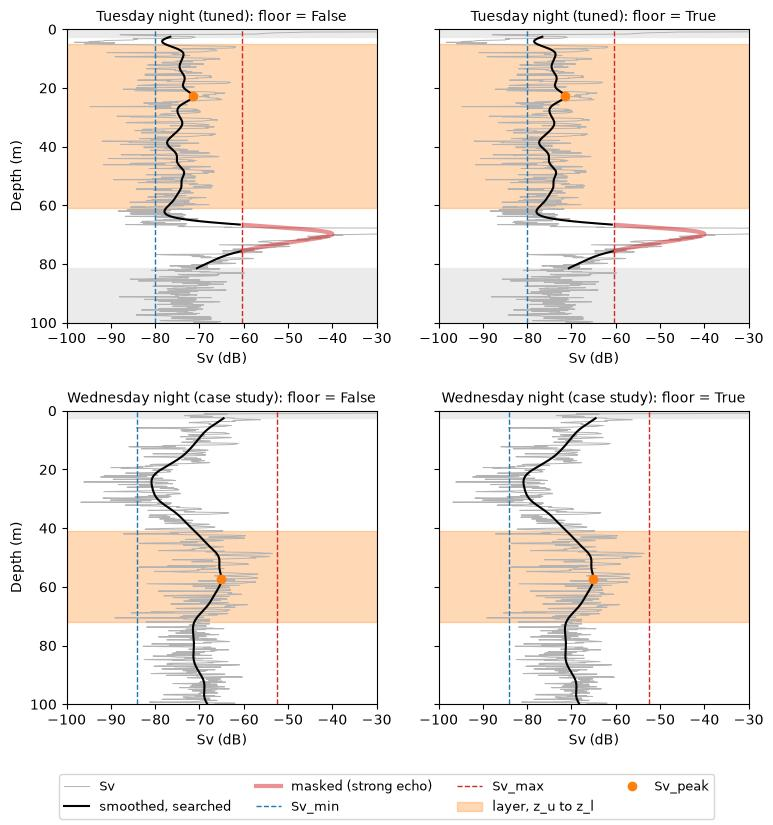

Tuesday night (simple), tuned settings


  floor  False: layer in 100.0% of pings, median thickness  37.6 m


  floor   True: layer in 100.0% of pings, median thickness  36.7 m
Wednesday night (harder), case study settings


  floor  False: layer in 100.0% of pings, median thickness  30.0 m


  floor   True: layer in 100.0% of pings, median thickness  30.0 m


In [12]:
panels("floor", (False, True))
plt.show()
table("floor", (False, True), (found, thick))

## 9. All pings: the two sets of settings

The white dots are the bounds `z_u` and `z_l` of each ping, and the red dots are the peak depth.

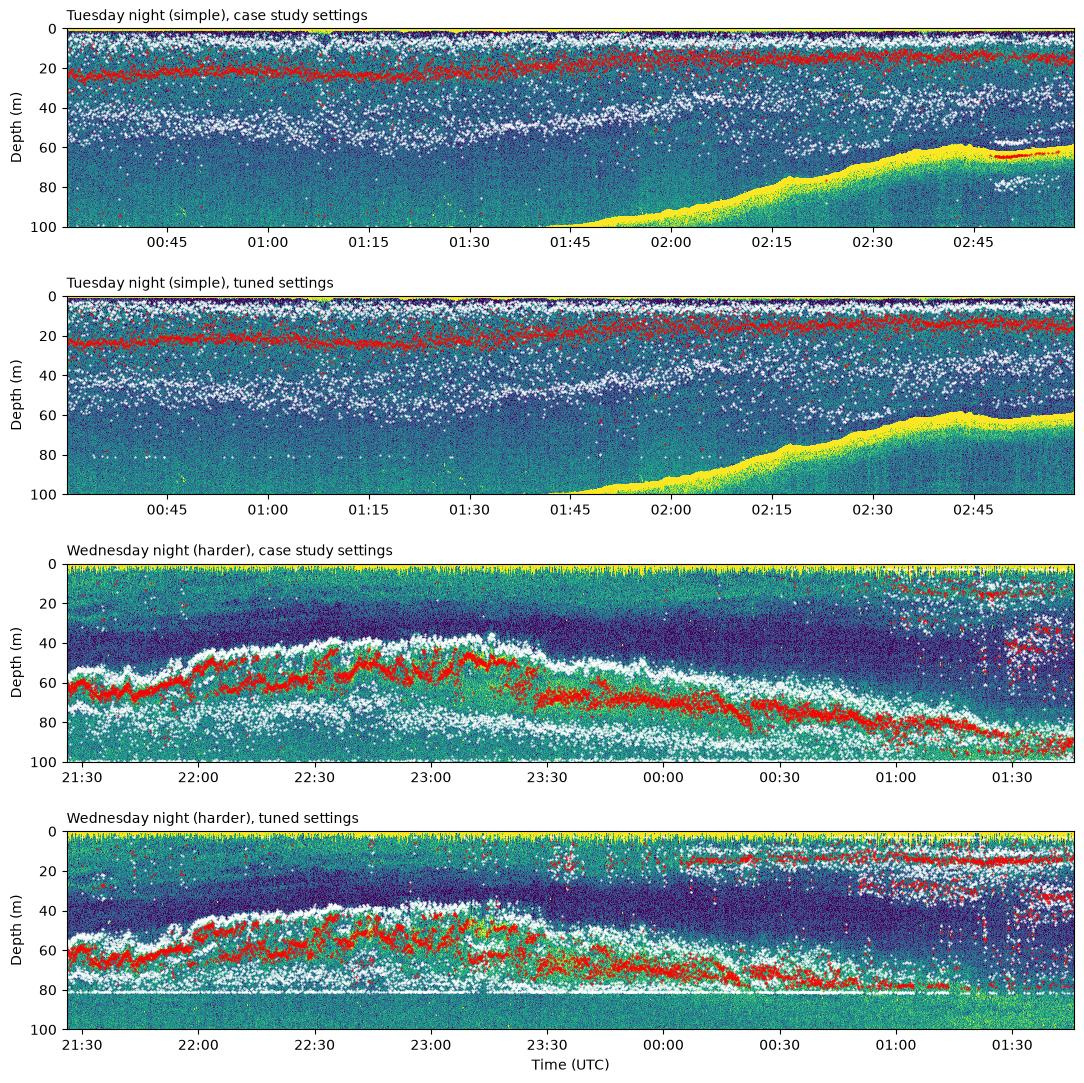

Tuesday night (simple)     case study: layer in 100.0% of pings, median thickness  36.6 m, median jump of the peak between pings  2.3 m
Tuesday night (simple)     tuned     : layer in 100.0% of pings, median thickness  36.7 m, median jump of the peak between pings  2.5 m
Wednesday night (harder)   case study: layer in 100.0% of pings, median thickness  30.0 m, median jump of the peak between pings  2.1 m
Wednesday night (harder)   tuned     : layer in  96.7% of pings, median thickness  19.1 m, median jump of the peak between pings  3.4 m


In [13]:
fig, axs = plt.subplots(4, 1, figsize=(13, 13))
R = {}
for row, (k, name) in enumerate((k, n) for k in D for n in SETTINGS):
    R[k, name] = ssl.detect(D[k]["sv"], D[k]["depth"], **SETTINGS[name])
    echogram(axs[row], k, R[k, name], title=f"{NAMES[k]}, {name} settings")
axs[-1].set_xlabel("Time (UTC)")
fig.subplots_adjust(hspace=0.35)
plt.show()
for (k, name), r in R.items():
    print(f"{NAMES[k]:26} {name:10}: {found(r)}, {thick(r)}, {jump(r)}")

- **Tuesday:** both sets find the layer near 20 m. With the case-study settings the seabed is taken as the
  layer in 77 pings, nearly all from 02:47 (the red dots at about 62 to 65 m); the tuned settings mask it.
- **Wednesday:** the tuned settings do not fit. Their 81.5 m bottom cuts off the layer's lower part: the
  lower bound sits at the bottom in 17% of the pings (the white line at 81.5 m). As the layer sinks below it,
  the detector picks features shallower than 45 m instead, in 25% of the pings, most of them after 00:50. The
  case-study settings follow the layer down until about 01:15, when it reaches the 100 m bottom and the
  detector picks weaker features above it.

Single pings are noisy, so the per-ping bounds are noisy as well. As the paper notes, they need filtering
over pings to give stable bounds. This filter is not part of the detector. Here it is a running median over
23 pings (about a minute), which skips pings without a layer, on each dataset with its own settings.

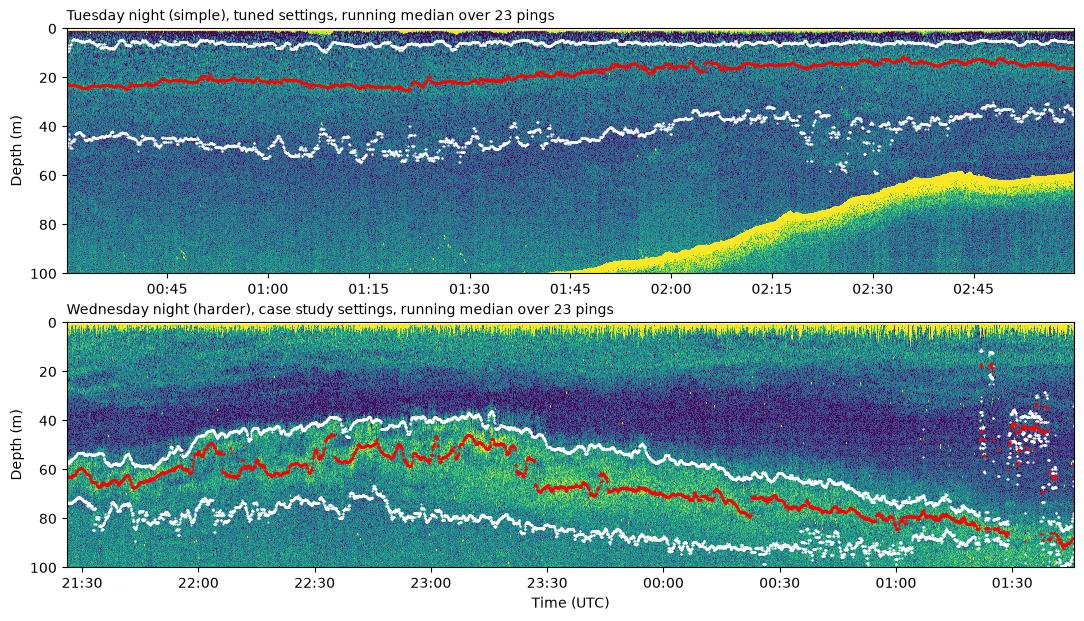

In [14]:
fig, axs = plt.subplots(2, 1, figsize=(13, 7))
for ax, k in zip(axs, D):
    echogram(ax, k, R[k, USE[k]], median=ssl.TUNED_MEDIAN, title=f"{NAMES[k]}, {USE[k]} settings, running median over 23 pings")
axs[-1].set_xlabel("Time (UTC)")
plt.show()

## 10. Tune it yourself

Pick a dataset and move a slider: the detector runs again on all its pings (about a second). The left panel
shows the echogram with the bounds and the peak, and the right panel shows the ping marked by the dotted
line. `median` is the running median of section 9 (1 = off). The buttons load either set of settings.

The panel needs a running Python kernel: open the notebook through the Binder link in the README, or locally,
and run all cells (Run > Run All Cells in JupyterLab). A static view, such as GitHub's, shows only the code.

In [15]:
@lru_cache(maxsize=32)
def run(k, *p):
    return ssl.detect(D[k]["sv"], D[k]["depth"], *p)


style, wide = {"description_width": "110px"}, w.Layout(width="440px")
opts = dict(continuous_update=False, style=style, layout=wide)
ui = dict(
    k=w.Dropdown(options=[(v, k) for k, v in NAMES.items()], value="tue_night", description="dataset",
                 style=style, layout=wide),
    depth_range=w.FloatRangeSlider(min=0, max=100, step=0.5, description="depth range", readout_format=".1f", **opts),
    sigma=w.FloatSlider(min=0, max=10, step=0.1, description="sigma (m)", **opts),
    sv_min=w.FloatSlider(min=-100, max=-55, step=0.5, description="sv_min (dB)", **opts),
    sv_max=w.FloatSlider(min=-70, max=-20, step=0.5, description="sv_max (dB)", **opts),
    rel_height=w.FloatSlider(min=0.05, max=1, step=0.05, description="rel_height", **opts),
    min_prominence=w.FloatSlider(min=0, max=10, step=0.5, description="min_prominence (dB)", **opts),
    min_width=w.FloatSlider(min=0, max=10, step=0.5, description="min_width (m)", **opts),
    floor=w.Checkbox(description="floor at sv_min", style=style),
    median=w.IntSlider(min=1, max=101, step=2, description="median (pings)", **opts),
    ping=w.IntSlider(value=EX["tue_night"], min=0, max=len(T["tue_night"]) - 1, description="ping", **opts),
)


def load(name):
    """Set the sliders to one set of settings."""
    p = SETTINGS[name]
    ui["depth_range"].value = (p["min_depth"], p["max_depth"])
    for key in ("sigma", "sv_min", "sv_max", "rel_height", "min_prominence", "min_width", "floor"):
        ui[key].value = p[key]
    ui["median"].value = ssl.TUNED_MEDIAN if name == "tuned" else 1


buttons = [w.Button(description=f"{name} settings") for name in SETTINGS]
for b, name in zip(buttons, SETTINGS):
    b.on_click(lambda _, name=name: load(name))


def new_dataset(change):
    ui["ping"].max = len(T[change["new"]]) - 1
    ui["ping"].value = EX[change["new"]]


ui["k"].observe(new_dataset, names="value")
load("tuned")


def show(k, depth_range, sigma, sv_min, sv_max, rel_height, min_prominence, min_width, floor, median, ping):
    if sv_min >= sv_max:
        print("sv_min must be below sv_max")
        return
    ping = min(ping, len(T[k]) - 1)
    p = dict(min_depth=depth_range[0], max_depth=depth_range[1], sigma=sigma, sv_min=sv_min, sv_max=sv_max,
             rel_height=rel_height, min_prominence=min_prominence, min_width=min_width, floor=floor)
    r = run(k, *p.values())
    fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5), sharey=True, gridspec_kw=dict(width_ratios=[3, 1]))
    echogram(a, k, r, median)
    a.axvline(T[k][ping], color="w", ls=":", lw=1)
    profile(b, k, ping, p=p)
    plt.show()
    f = r["found"]
    if not f.any():
        print("no layer found in any ping")
        return
    print(f"layer found in {100 * f.mean():.1f}% of pings; medians: z_u {np.median(r['z_u'][f]):.1f} m, "
          f"z_l {np.median(r['z_l'][f]):.1f} m, I {np.median(r['intensity'][f]):.2f}")


out = w.interactive_output(show, ui)
left = w.VBox([ui[key] for key in ("k", "depth_range", "sigma", "sv_min", "sv_max", "rel_height")])
right = w.VBox([ui[key] for key in ("min_prominence", "min_width", "floor", "median", "ping")] + [w.HBox(buttons)])
display(w.HBox([left, right]), out)

## References

- Peña M, Munuera-Fernández I, Nogueira E, González-Quirós R (2021). First recording of a bathypelagic deep
  scattering layer in the Bay of Biscay. *Progress in Oceanography* 198: 102669.
  https://doi.org/10.1016/j.pocean.2021.102669
- Virtanen P, Gommers R, Oliphant TE, et al. (2020). SciPy 1.0: fundamental algorithms for scientific
  computing in Python. *Nature Methods* 17: 261–272. https://doi.org/10.1038/s41592-019-0686-2
- Lee W-J, Setiawan L, Tuguinay C, Mayorga E, Staneva V (2024). Interoperable and scalable echosounder data
  processing with Echopype. *ICES Journal of Marine Science* 81(10): 1941–1951.
  https://doi.org/10.1093/icesjms/fsae133